In [22]:

import pandas as pd
import joblib

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df.dropna(inplace=True)
df.drop(columns=["customerID"], inplace=True)

print(df.head())
print("Dataset loaded successfully")


   gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  Female              0     Yes         No       1           No   
1    Male              0      No         No      34          Yes   
2    Male              0      No         No       2          Yes   
3    Male              0      No         No      45           No   
4  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity OnlineBackup  \
0  No phone service             DSL             No          Yes   
1                No             DSL            Yes           No   
2                No             DSL            Yes          Yes   
3  No phone service             DSL            Yes           No   
4                No     Fiber optic             No           No   

  DeviceProtection TechSupport StreamingTV StreamingMovies        Contract  \
0               No          No          No              No  Month-to-month   
1              Yes          No  

In [23]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

X = df.drop("Churn", axis=1)
y = df["Churn"].map({"No": 0, "Yes": 1})

num_cols = X.select_dtypes(include=["int64", "float64"]).columns
cat_cols = X.select_dtypes(include=["object"]).columns

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100, random_state=42
    ))
])

model.fit(X_train, y_train)
print("Model trained successfully")


Model trained successfully


In [24]:

joblib.dump(model, "churn_model.joblib")
print("Model saved successfully")


Model saved successfully


In [25]:

loaded_model = joblib.load("churn_model.joblib")
print("Saved model loaded successfully")


Saved model loaded successfully


In [26]:

sample = X_test.iloc[[0]]

prediction = loaded_model.predict(sample)[0]
probability = loaded_model.predict_proba(sample)[0][1]

print("Prediction:", "Churn" if prediction == 1 else "No Churn")
print("Churn Probability:", round(probability * 100, 2), "%")


Prediction: No Churn
Churn Probability: 1.0 %


In [27]:

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import cross_val_score

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

print("Models ready for comparison")


Models ready for comparison


In [28]:

results = {}

for name, classifier in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    scores = cross_val_score(
        pipeline, X_train, y_train, cv=5, scoring="accuracy"
    )

    results[name] = scores.mean()
    print(name, "Accuracy:", round(scores.mean() * 100, 2), "%")


Logistic Regression Accuracy: 80.25 %
Random Forest Accuracy: 78.54 %
Gradient Boosting Accuracy: 80.14 %


In [29]:

from sklearn.model_selection import GridSearchCV

gb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", GradientBoostingClassifier(random_state=42))
])

parameters = {
    "classifier__n_estimators": [100, 150],
    "classifier__learning_rate": [0.05, 0.1],
    "classifier__max_depth": [2, 3]
}

search = GridSearchCV(
    gb_pipeline, parameters, cv=5, scoring="accuracy", n_jobs=-1
)
search.fit(X_train, y_train)

best_model = search.best_estimator_

print("Best Parameters:", search.best_params_)
print("Best CV Accuracy:", round(search.best_score_ * 100, 2), "%")


Best Parameters: {'classifier__learning_rate': 0.05, 'classifier__max_depth': 3, 'classifier__n_estimators': 100}
Best CV Accuracy: 80.43 %


In [30]:

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1 Score:", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))


Accuracy: 0.7925
Precision: 0.6367
Recall: 0.5107
F1 Score: 0.5668
ROC-AUC: 0.8385


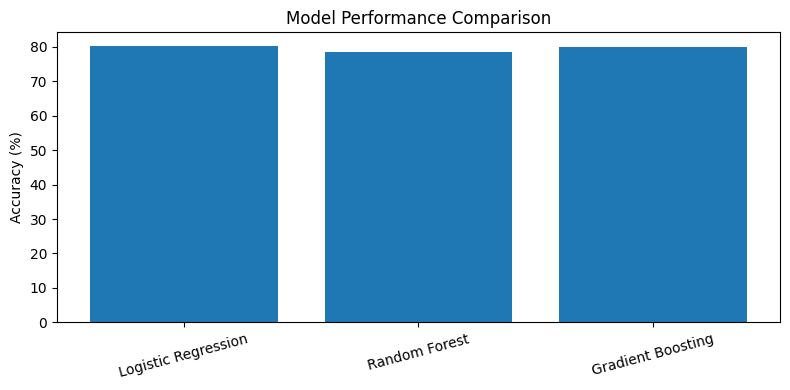

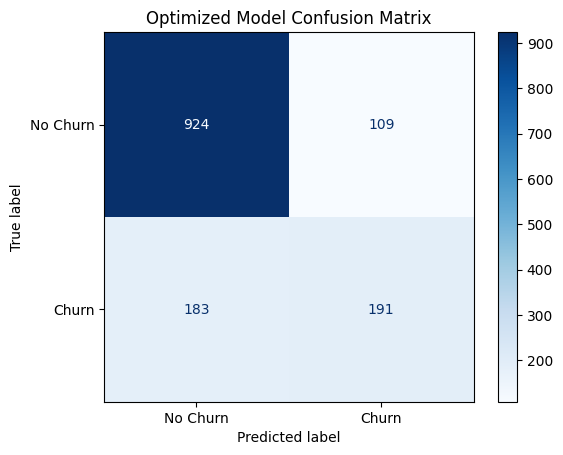

In [31]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

plt.figure(figsize=(8, 4))
plt.bar(results.keys(), [v * 100 for v in results.values()])
plt.ylabel("Accuracy (%)")
plt.title("Model Performance Comparison")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["No Churn", "Churn"],
    cmap="Blues"
)
plt.title("Optimized Model Confusion Matrix")
plt.show()


In [32]:

advanced_df = df.copy()

advanced_df["TenureGroup"] = pd.cut(
    advanced_df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["New", "Short", "Medium", "Long"]
)

advanced_df["AvgMonthlySpend"] = (
    advanced_df["TotalCharges"] /
    advanced_df["tenure"].replace(0, 1)
)

print(advanced_df[["tenure", "TenureGroup", "AvgMonthlySpend"]].head())


   tenure TenureGroup  AvgMonthlySpend
0       1         New        29.850000
1      34      Medium        55.573529
2       2         New        54.075000
3      45      Medium        40.905556
4       2         New        75.825000


In [33]:

X_adv = advanced_df.drop("Churn", axis=1)
y_adv = advanced_df["Churn"].map({"No": 0, "Yes": 1})

X_train_adv, X_test_adv, y_train_adv, y_test_adv = train_test_split(
    X_adv, y_adv, test_size=0.2, random_state=42, stratify=y_adv
)

num_adv = X_adv.select_dtypes(include=["int64", "float64"]).columns
cat_adv = X_adv.select_dtypes(include=["object", "category"]).columns

preprocessor_adv = ColumnTransformer([
    ("num", StandardScaler(), num_adv),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_adv)
])

print("Advanced workflow data prepared")


Advanced workflow data prepared


In [34]:

advanced_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

trained_models = {}

for name, classifier in advanced_models.items():
    pipe = Pipeline([
        ("preprocessor", preprocessor_adv),
        ("classifier", classifier)
    ])
    pipe.fit(X_train_adv, y_train_adv)
    trained_models[name] = pipe

    print(name, "trained successfully")


Logistic Regression trained successfully
Random Forest trained successfully
Gradient Boosting trained successfully


In [35]:

from sklearn.metrics import accuracy_score

accuracies = {}

for name, pipe in trained_models.items():
    predictions = pipe.predict(X_test_adv)
    accuracies[name] = accuracy_score(y_test_adv, predictions)

best_name = max(accuracies, key=accuracies.get)
best_advanced_model = trained_models[best_name]

print("Model Comparison:")
for name, score in accuracies.items():
    print(name, ":", round(score * 100, 2), "%")

print("\nSelected Model:", best_name)


Model Comparison:
Logistic Regression : 79.25 %
Random Forest : 78.39 %
Gradient Boosting : 79.46 %

Selected Model: Gradient Boosting


In [36]:

new_customer = X_test_adv.iloc[[0]]

prediction = best_advanced_model.predict(new_customer)[0]
probability = best_advanced_model.predict_proba(new_customer)[0][1]

print("Customer Churn Prediction")
print("-------------------------")
print("Result:", "Likely to Churn" if prediction == 1 else "Not Likely to Churn")
print("Churn Probability:", round(probability * 100, 2), "%")

if probability >= 0.5:
    print("Action: Offer a retention discount or personalized service.")
else:
    print("Action: Continue regular customer engagement.")


Customer Churn Prediction
-------------------------
Result: Not Likely to Churn
Churn Probability: 2.55 %
Action: Continue regular customer engagement.
